# Original group notebook (archived as-is). Data paths point to the team's private Google Drive; see the repository README to run the refactored code.

# We have a README file to explain all our main files.

In [ ]:
# Baseline colleberative filtering - knn method.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Careful: It might be better to install these outside Jupyter
!pip install scikit-surprise
!pip install seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.4/154.4 kB 2.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-surprise: filename=scikit_surprise-1.1.4-cp311-cp311-linux_x86_64.whl size=2469531 sha256=d170924e0b58d84e06ff0e26dea9566b77bc93eabbe2cd0c03a17203b54dcacd
  Stored in directory: /root/.cache/pip/wheels/2a/8f/6e/7e2899163e2d85d8266daab4aa1cdabec7a6c56f83c015b5af
Successfully built scikit-surprise


In [ ]:
!pip install "numpy<2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 49.4 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-contrib-python 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.26.4 which is incompatible.


In [ ]:
import pandas as pd
games_df = pd.read_csv("/content/drive/My Drive/9727-group/user_game_with_genre.csv")#, nrows=8095400
display(games_df)

,app_id,is_recommended,hours,user_id,genre
0,975370,True,36.3,51580,"RPG,Simulation,Strategy"
1,304390,False,11.5,2586,Action
2,1085660,True,336.5,253880,"Action,Adventure,Free to Play"
3,703080,True,27.4,259432,"Casual,Simulation,Strategy"
4,526870,True,7.9,23869,"Adventure,Indie,Simulation,Strategy,Early Access"
...,...,...,...,...,...
40954823,633230,True,41.0,1606890,Action
40954824,758870,False,8.0,1786254,"Adventure,Indie,RPG,Simulation,Early Access"
40954825,696170,False,2.0,6370324,Action
40954826,696170,True,4.0,1044289,Action


In [ ]:
games_df['is_recommended'] = games_df['is_recommended'].astype(float)
# games_df.loc[games_df['is_recommended'] == 0, 'is_recommended'] = 0.1

user_counts = games_df['user_id'].value_counts()
item_counts = games_df['app_id'].value_counts()
filtered_df = games_df[
    games_df['user_id'].isin(user_counts[user_counts >= 100].index) &
    games_df['app_id'].isin(item_counts[item_counts >= 1000].index)
]
display(filtered_df)
item_counts = games_df['app_id'].value_counts()
print(item_counts)

,app_id,is_recommended,hours,user_id,genre
151,1196590,1.0,19.0,5935019,Action
422,435150,1.0,199.9,6334645,"Adventure,RPG,Strategy"
425,275850,1.0,13.6,6484333,"Action,Adventure"
691,105600,1.0,911.8,10383001,"Action,Adventure,Indie,RPG"
712,1794680,1.0,77.3,11659871,"Action,Casual,Indie,RPG,Early Access"
...,...,...,...,...,...
40954660,253430,0.0,1.0,2444255,"Violent,Action,Adventure,Indie"
40954757,897450,1.0,6.0,8857084,"Action,Adventure,Casual,Indie"
40954798,1818450,1.0,1.0,13261742,"Action,Adventure,Massively Multiplayer,RPG"
40954805,362960,1.0,35.0,7858713,"Adventure,RPG"


app_id
440        319492
252490     270684
1091500    226414
730        219737
570        216914
            ...  
1875530         1
2234030         1
666640          1
2149870         1
1483430         1
Name: count, Length: 37412, dtype: int64


In [ ]:
filtered_df.to_csv("/content/drive/My Drive/9727-group/filtered_games.csv", index=False)

In [ ]:
specific_game_ratings = filtered_df[filtered_df['app_id'] == 304390]
print(f"Ratings for game ID 304390:\n {specific_game_ratings}")

Ratings for game ID 304390:
           app_id  is_recommended  hours   user_id   genre
2491      304390             1.0  349.8    804746  Action
45060     304390             1.0  110.3   5683785  Action
63745     304390             1.0    4.5   7783960  Action
89239     304390             1.0   30.6   8093776  Action
98265     304390             0.0   10.5  11397610  Action
...          ...             ...    ...       ...     ...
34599646  304390             1.0    2.1   6906027  Action
34603009  304390             1.0   50.2  13257088  Action
34603267  304390             1.0  111.9  12957974  Action
34603387  304390             1.0   13.5   7888693  Action
34603875  304390             1.0    7.6  13962074  Action

[974 rows x 5 columns]


In [ ]:
specific_game_ratings = filtered_df[filtered_df['user_id'] == 22793]
print(f"Ratings for game ID 304390:\n {specific_game_ratings}")

Ratings for game ID 304390:
 Empty DataFrame
Columns: [app_id, is_recommended, hours, user_id, genre]
Index: []


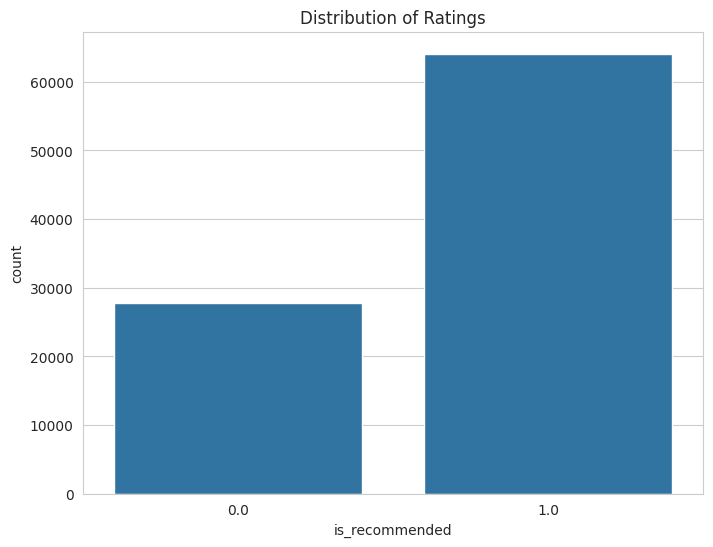

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.figure(figsize=(8,6))
sns.countplot(x='is_recommended', data=games_df[games_df['app_id'] == 304390])
plt.title('Distribution of Ratings')
plt.show()

In [ ]:
import pandas as pd
filtered_df = pd.read_csv("/content/drive/My Drive/9727-group/filtered_games.csv")
display(filtered_df)

,app_id,is_recommended,hours,user_id,genre
0,1196590,1.0,19.0,5935019,Action
1,435150,1.0,199.9,6334645,"Adventure,RPG,Strategy"
2,275850,1.0,13.6,6484333,"Action,Adventure"
3,105600,1.0,911.8,10383001,"Action,Adventure,Indie,RPG"
4,1794680,1.0,77.3,11659871,"Action,Casual,Indie,RPG,Early Access"
...,...,...,...,...,...
950350,253430,0.0,1.0,2444255,"Violent,Action,Adventure,Indie"
950351,897450,1.0,6.0,8857084,"Action,Adventure,Casual,Indie"
950352,1818450,1.0,1.0,13261742,"Action,Adventure,Massively Multiplayer,RPG"
950353,362960,1.0,35.0,7858713,"Adventure,RPG"


In [ ]:
unique_app_count = filtered_df['app_id'].nunique()
print(f"Totally as {unique_app_count} app_id")

Totally as 3654 app_id


In [ ]:
from surprise import KNNBasic
from surprise import Dataset, Reader

reader = Reader(rating_scale=(0, 1))
data = Dataset.load_from_df(filtered_df[['user_id', 'app_id', 'is_recommended']], reader)

In [ ]:
from surprise.model_selection import train_test_split

trainset, testset = train_test_split(data, test_size=0.2, random_state=42)

In [ ]:
# method 1: KNN.
from surprise import KNNBasic
# item-based CF
sim_options = {
    'name': 'cosine',
    'user_based': False     # Item-based
}
algo = KNNBasic()
algo.fit(trainset)

Computing the msd similarity matrix...
Done computing similarity matrix.


In [ ]:
predictions = algo.test(testset)
for pred in predictions[4000:4008]:
    print(pred)

user: 12486547   item: 206190     r_ui = 1.00   est = 0.97   {'actual_k': 40, 'was_impossible': False}
user: 12499337   item: 42700      r_ui = 1.00   est = 0.97   {'actual_k': 40, 'was_impossible': False}
user: 11349715   item: 300        r_ui = 1.00   est = 0.95   {'actual_k': 40, 'was_impossible': False}
user: 9664325    item: 1238860    r_ui = 1.00   est = 0.92   {'actual_k': 40, 'was_impossible': False}
user: 6036016    item: 308040     r_ui = 0.00   est = 0.88   {'actual_k': 40, 'was_impossible': False}
user: 1213142    item: 221040     r_ui = 1.00   est = 0.82   {'actual_k': 40, 'was_impossible': False}
user: 9102872    item: 19980      r_ui = 0.00   est = 0.83   {'actual_k': 40, 'was_impossible': False}
user: 2581764    item: 859580     r_ui = 0.00   est = 0.74   {'actual_k': 40, 'was_impossible': False}


In [ ]:
from surprise import accuracy

accuracy.rmse(predictions)

RMSE: 0.3644


0.36438820282135714

In [ ]:
def get_top_n_recommendations(predictions, n=10):
    top_n = {}

    for uid, iid, true_r, est, _ in predictions:
        top_n.setdefault(uid, []).append((iid, est))

    for uid, user_ratings in top_n.items():
        user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = user_ratings[:n]

    return top_n

top_n = get_top_n_recommendations(predictions, n=10)

for uid, user_ratings in list(top_n.items())[:3]:
    print(f"Top 10 recommendations for user {uid}: {', '.join([str(iid) for iid, _ in user_ratings])}")

Top 10 recommendations for user 142058: 498240, 1289310, 548430, 35140, 307690, 233610, 278360, 224760, 227780, 812810
Top 10 recommendations for user 8496478: 2630, 555160, 1167630, 323190, 815370, 613100, 512900, 975370, 496300, 1089130
Top 10 recommendations for user 9032110: 225080, 206190, 336140, 224760, 213670, 35720, 49520, 49600, 1057090, 107100


In [ ]:
def get_top_n_recommendations_with_scores(predictions, n=10):
    top_n = {}
    for uid, iid, true_r, est, _ in predictions:
        top_n.setdefault(uid, []).append((iid, est))

    for uid, user_ratings in top_n.items():
        user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = user_ratings[:n]

    return top_n

top_n = get_top_n_recommendations_with_scores(predictions, n=10)

for uid, user_ratings in list(top_n.items())[:5]:
    print(f"Top 10 recommendations for user {uid}:")
    for iid, est in user_ratings:
        print(f"    Game ID: {iid} | Predicted Score: {est:.3f}")


Top 10 recommendations for user 142058:
    Game ID: 498240 | Predicted Score: 1.000
    Game ID: 1289310 | Predicted Score: 1.000
    Game ID: 548430 | Predicted Score: 0.975
    Game ID: 35140 | Predicted Score: 0.975
    Game ID: 307690 | Predicted Score: 0.950
    Game ID: 233610 | Predicted Score: 0.950
    Game ID: 278360 | Predicted Score: 0.950
    Game ID: 224760 | Predicted Score: 0.925
    Game ID: 227780 | Predicted Score: 0.925
    Game ID: 812810 | Predicted Score: 0.925
Top 10 recommendations for user 8496478:
    Game ID: 2630 | Predicted Score: 1.000
    Game ID: 555160 | Predicted Score: 1.000
    Game ID: 1167630 | Predicted Score: 0.975
    Game ID: 323190 | Predicted Score: 0.975
    Game ID: 815370 | Predicted Score: 0.950
    Game ID: 613100 | Predicted Score: 0.950
    Game ID: 512900 | Predicted Score: 0.925
    Game ID: 975370 | Predicted Score: 0.900
    Game ID: 496300 | Predicted Score: 0.825
    Game ID: 1089130 | Predicted Score: 0.800
Top 10 recommendati

In [ ]:
# precison and recall of the testset with true label.
from collections import defaultdict

def precision_recall_at_k(predictions, k=10, threshold=0.5):
    '''Return precision and recall at k metrics for each user.'''

    # Record the precsions of each user
    user_est_true = defaultdict(list)
    for uid, iid, true_r, est, _ in predictions:
        user_est_true[uid].append((est, true_r))

    precisions = {}
    recalls = {}

    for uid, user_ratings in user_est_true.items():
        # We range the score
        user_ratings.sort(key=lambda x: x[0], reverse=True)
        # Taking the topk higherst score.
        top_k = user_ratings[:k]
        n_rel_and_rec_k = sum((true_r >= threshold) for (_, true_r) in top_k)
        n_rel = sum((true_r >= threshold) for (_, true_r) in user_ratings)
        n_rec_k = k

        # aviod x/0 case.
        precision = n_rel_and_rec_k / n_rec_k if n_rec_k else 0
        recall = n_rel_and_rec_k / n_rel if n_rel else 0

        precisions[uid] = precision
        recalls[uid] = recall

    return precisions, recalls
# calculate precision and recall
precisions, recalls = precision_recall_at_k(predictions, k=10, threshold=0.5)

# taking the average value.
avg_precision = sum(precisions.values()) / len(precisions)
avg_recall = sum(recalls.values()) / len(recalls)

print(f"Average Precision@10: {avg_precision:.4f}")
print(f"Average Recall@10: {avg_recall:.4f}")

Average Precision@10: 0.8567
Average Recall@10: 0.5717
